# Milestone 3 — Predicting Google Play install tiers: classification and regression
Fifteen classifiers and twelve regressors are tuned, trained and compared, plus an extra experiment (5b) that retrains the MLP with weighted cross-entropy and focal loss for the skewed tiers; all results appear in this notebook, ready for the ACM report.

* **Split:** one 80/20 split per task, stratified on the 4 install tiers (Low ≤10k · Moderate ≤100k · High ≤1M · Very High >1M). Every final model is scored on the whole held-out 20% (~462k apps); `F1 (common 50k)` is the same score on a fixed stratified 50k subset of it, used for ranking.
* **Data size:** all 1.85M training rows, except KNN (200k) and RBF SVM/SVR (50k), whose memory grows quadratically.
* **Tuning:** 3-fold grid search (every setting tried) on a stratified 150k training sample (10k for the RBF models) (macro-F1 for classification, RMSE for regression); the best setting is refit on the full training set.
* **Metrics:** regression predictions are binned into the same 4 tiers, so accuracy and macro precision / recall / F1 are comparable across both tasks; classifiers use balanced class weights.

**1 · Setup and data.** Mounts Drive and loads both CSVs as `float32` (leakage columns dropped).

In [ ]:
import os, gc, time, inspect, warnings, hashlib, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
from IPython.display import display
from sklearn import metrics as skm
from sklearn.base import clone, BaseEstimator, ClassifierMixin, RegressorMixin
from sklearn.cluster import MiniBatchKMeans
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold, ParameterGrid
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression, Perceptron, LinearRegression, Ridge, Lasso, BayesianRidge
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import LinearSVC, SVC, LinearSVR, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor, AdaBoostClassifier, AdaBoostRegressor,
                              BaggingClassifier, BaggingRegressor, HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier, MLPRegressor

warnings.filterwarnings('ignore', category=ConvergenceWarning)
drive.mount('/content/drive')
DATA_DIR = '/content/drive/MyDrive/ML-Datasets'
CLF_PATH, REG_PATH = (os.path.join(DATA_DIR, f) for f in ('googleplaystore_classification.csv', 'google_playstore_cleaned.csv'))

SEED, QUICK, QUICK_ROWS = 42, False, 100_000          # QUICK=True: fast dry run on a random 100k rows
TUNE_N, TUNE_CV, KNN_N, SVM_N, SVM_TUNE_N, EVAL_N = 150_000, 3, 200_000, 50_000, 10_000, 50_000
MAX_ITER = 24                                         # grids up to this size are searched in full
CKPT = os.path.join(DATA_DIR, 'checkpoints_quick' if QUICK else 'checkpoints'); os.makedirs(CKPT, exist_ok=True)
CLASS_NAMES = ['Low', 'Moderate', 'High', 'Very High']
EDGES = np.log1p([1e4, 1e5, 1e6]) + 1e-6              # tier cut points in log(1 + installs) space
LEAK = ['Maximum Installs', 'Minimum Installs', 'Installs', 'Rating Count']
plt.rcParams.update({'figure.dpi': 130, 'savefig.bbox': 'tight'})

def load(path, drop, target, ty):
    cols = [c for c in pd.read_csv(path, nrows=0).columns if c not in drop + [target]]
    df = pd.read_csv(path, usecols=cols + [target], dtype={**dict.fromkeys(cols, np.float32), target: ty})
    return cols, df[cols].to_numpy(np.float32), df[target]

cols_c, Xc, yc = load(CLF_PATH, LEAK + ['Log_Max_Installs'], 'Installs_Class', str)
cols_r, Xr, yr = load(REG_PATH, LEAK, 'Log_Max_Installs', np.float32)
yc, yr = yc.map({n: i for i, n in enumerate(CLASS_NAMES)}).to_numpy(np.int8), yr.to_numpy(np.float32)
print(f'classification {Xc.shape} | regression {Xr.shape}')

Mounted at /content/drive
classification (2312944, 60) | regression (2312944, 60)


**2 · Split and subsamples.** Both tasks get a tier-stratified split, `Size_MB` standardised with training statistics, and fixed stratified subsamples reused by every model.

In [ ]:
def sub(s, n):
    return np.arange(len(s)) if n >= len(s) else np.sort(train_test_split(np.arange(len(s)), train_size=n, stratify=s, random_state=SEED)[0])

def prep(task, X, y, cols):
    if QUICK:
        k = np.random.default_rng(SEED).choice(len(y), min(QUICK_ROWS, len(y)), replace=False); X, y = X[k], y[k]
    strat = y if task == 'clf' else np.digitize(y, EDGES)
    tr, te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=strat, random_state=SEED)
    if 'Size_MB' in cols:
        j = cols.index('Size_MB'); X[:, j] = (X[:, j] - X[tr, j].mean()) / X[tr, j].std()
    ev = sub(strat[te], EVAL_N)
    return dict(Xtr=X[tr], ytr=y[tr], Str=strat[tr], Xte=X[te], yte=y[te], Xev=X[te][ev], yev=y[te][ev], ev=ev)

D = {'clf': prep('clf', Xc, yc, cols_c), 'reg': prep('reg', Xr, yr, cols_r)}
del Xc, Xr; gc.collect()
for t, d in D.items(): print(f"{t}: train {d['Xtr'].shape[0]:,} | full test {d['Xte'].shape[0]:,} | common evaluation subset {d['Xev'].shape[0]:,}")

clf: train 1,850,355 | full test 462,589 | common evaluation subset 50,000
reg: train 1,850,355 | full test 462,589 | common evaluation subset 50,000


**3 · Helpers.** `run()` tunes (if a grid is given), fits the best setting, scores it on the full 20% test set and checkpoints the result to Drive (a model is skipped on rerun unless its code changed); `report()` shows the table, bar chart, confusion matrix and per-tier scores. Mode `'torch'` (used in 5b) trains on all rows like `'full'` but runs the grid search in one process, so PyTorch models don't fight over the GPU.


In [ ]:
tier = lambda task, v: v if task == 'clf' else np.digitize(v, EDGES)
RESULTS, TUNING, PRED = [], [], {}
S = lambda name, est, grid=None, mode='full', bal=False: (name, est, grid, mode, bal)

def metrics(task, yt, p):
    r = {'R2': skm.r2_score(yt, p), 'RMSE': np.sqrt(skm.mean_squared_error(yt, p)), 'MAE': skm.mean_absolute_error(yt, p)} if task == 'reg' else {}
    t, q = tier(task, yt), tier(task, p)
    P, R, F, _ = skm.precision_recall_fscore_support(t, q, average='macro', zero_division=0)
    return r | {'Accuracy': skm.accuracy_score(t, q), 'Precision': P, 'Recall': R, 'F1': F}

class MoE(BaseEstimator):
    """Mixture of experts: linear experts + softmax gate, trained by hard EM from a k-means start."""
    def __init__(self, n_experts=8, n_iter=3, random_state=SEED):
        self.n_experts, self.n_iter, self.random_state = n_experts, n_iter, random_state

    def fit(self, X, y):
        self.classes_ = np.unique(y) if isinstance(self, ClassifierMixin) else None
        z = MiniBatchKMeans(self.n_experts, n_init=3, random_state=self.random_state).fit_predict(X)
        for it in range(self.n_iter + 1):           # M-step: fit each expert on its apps
            self.experts_ = [self._fit_expert(X[z == k], y[z == k]) if (z == k).any() else None for k in range(self.n_experts)]
            if it < self.n_iter:                     # hard E-step: give each app to the expert that explains it best
                z = np.column_stack([np.full(len(y), np.inf) if e is None else self._loss(e, X, y) for e in self.experts_]).argmin(1)
        self.gate_ = LogisticRegression(max_iter=300).fit(X, z) if np.unique(z).size > 1 else z[0]
        return self

    def _mix(self, X):                               # gate-weighted sum of the experts' outputs
        if not isinstance(self.gate_, LogisticRegression): return self._out(self.experts_[self.gate_], X)
        G = self.gate_.predict_proba(X)
        return sum(G[:, [j]] * self._out(self.experts_[k], X) for j, k in enumerate(self.gate_.classes_))

class MoEClassifier(ClassifierMixin, MoE):
    def _fit_expert(self, X, y):
        return LogisticRegression(class_weight='balanced', max_iter=300).fit(X, y) if np.unique(y).size > 1 else y[0]
    def _out(self, e, X):
        P = np.zeros((len(X), len(self.classes_)))
        if isinstance(e, LogisticRegression): P[:, np.searchsorted(self.classes_, e.classes_)] = e.predict_proba(X)
        else: P[:, np.searchsorted(self.classes_, e)] = 1
        return P
    def _loss(self, e, X, y): return -np.log(self._out(e, X)[np.arange(len(y)), np.searchsorted(self.classes_, y)] + 1e-9)
    def predict_proba(self, X): return self._mix(X)
    def predict(self, X): return self.classes_[self._mix(X).argmax(1)]

class MoERegressor(RegressorMixin, MoE):
    def _fit_expert(self, X, y): return LinearRegression().fit(X, y)
    def _out(self, e, X): return e.predict(X)[:, None]
    def _loss(self, e, X, y): return (e.predict(X) - y) ** 2
    def predict(self, X): return self._mix(X)[:, 0]

def run(task, name, est, grid=None, mode='full', bal=False):
    if (task, name) in PRED: return
    d, clf = D[task], task == 'clf'
    key = hashlib.md5(repr(('v4', task, name, est, grid, mode, bal, QUICK, TUNE_N, MAX_ITER)).encode()).hexdigest()
    ck = os.path.join(CKPT, f"{task}_{name.replace(' ', '_').replace('(', '').replace(')', '')}.pkl")

    if os.path.exists(ck):
        saved = pickle.load(open(ck, 'rb'))
        if saved['key'] == key:
            TUNING.append(saved['tuning']); RESULTS.append(saved['result']); PRED[(task, name)] = saved['pred']
            r = saved['result']
            print(f"{name:20s} F1={r['F1']:.4f}  Acc={r['Accuracy']:.4f}  Prec={r['Precision']:.4f}  Rec={r['Recall']:.4f}  ({r['Fit (s)']:.0f}s) [restored]")
            return
    tr = slice(None) if mode in ('full', 'torch') else sub(d['Str'], KNN_N if mode == 'knn' else SVM_N)
    tuned, cv_score = {}, {}
    if grid:
        tp = sub(d['Str'], SVM_TUNE_N if mode == 'svm' else TUNE_N)        # tier-stratified: works for both tasks
        Xt, yt = d['Xtr'][tp], d['ytr'][tp]
        args = dict(scoring='f1_macro' if clf else 'neg_root_mean_squared_error', n_jobs=1 if mode == 'torch' else -1, refit=False,
                    cv=list(StratifiedKFold(TUNE_CV, shuffle=True, random_state=SEED).split(Xt, d['Str'][tp])))
        search = (GridSearchCV(est, grid, **args) if len(ParameterGrid(grid)) <= MAX_ITER     # small grid: try all
                  else RandomizedSearchCV(est, grid, n_iter=MAX_ITER, random_state=SEED, **args))
        search.fit(Xt, yt, **({'sample_weight': compute_sample_weight('balanced', yt)} if bal else {}))
        tuned = search.best_params_
        cv_score = {'CV macro-F1' if clf else 'CV RMSE': abs(search.best_score_)}
    est = clone(est).set_params(**tuned)
    trow = {'Task': task, 'Model': name, 'Selected hyperparameters': ', '.join(f'{k}={v}' for k, v in tuned.items()) or 'fixed (not tuned)', **cv_score}
    kw = {'sample_weight': compute_sample_weight('balanced', d['ytr'][tr])} if bal else {}


    t0 = time.perf_counter()
    m = est.fit(d['Xtr'][tr], d['ytr'][tr], **kw)
    fit_s = time.perf_counter() - t0

    p = m.predict(d['Xte'])
    r = {'Task': task, 'Model': name, 'Train rows': d['ytr'][tr].size, 'Fit (s)': fit_s, 'Scored on': 'full test', **metrics(task, d['yte'], p),
         'F1 (common 50k)': metrics(task, d['yev'], p[d['ev']])['F1']}

    TUNING.append(trow); RESULTS.append(r); PRED[(task, name)] = p
    pickle.dump({'key': key, 'tuning': trow, 'result': r, 'pred': p}, open(ck, 'wb'))
    print(f"{name:20s} F1={r['F1']:.4f}  Acc={r['Accuracy']:.4f}  Prec={r['Precision']:.4f}  Rec={r['Recall']:.4f}  ({fit_s:.0f}s)")

def report(task):
    df = pd.DataFrame(RESULTS).query('Task == @task').drop(columns='Task').dropna(axis=1, how='all').sort_values('F1 (common 50k)', ascending=False).reset_index(drop=True)
    hi, lo = [c for c in ('R2', 'Accuracy', 'Precision', 'Recall', 'F1') if c in df], [c for c in ('RMSE', 'MAE') if c in df]
    display(df.style.format({'Train rows': '{:,.0f}', 'Fit (s)': '{:.0f}'}, precision=4).highlight_max(subset=hi, props='font-weight:bold;background-color:#d9ead3')
            .highlight_min(subset=lo, props='font-weight:bold;background-color:#d9ead3').hide(axis='index'))
    df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1']].iloc[::-1].plot.barh(figsize=(8, .5 * len(df) + 1.5), width=.8)
    plt.xlabel('Score (macro-averaged over install tiers)'); plt.title(f"{'Classification' if task == 'clf' else 'Regression'}: model comparison"); plt.legend(loc='lower right'); plt.show()
    best = df.loc[0, 'Model']; p = PRED[(task, best)]; yt = D[task]['yte'] if len(p) == len(D[task]['yte']) else D[task]['yev']; t, q = tier(task, yt), tier(task, p)
    fig, ax = plt.subplots(1, 2 if task == 'reg' else 1, figsize=(10 if task == 'reg' else 5.5, 4.5), squeeze=False)
    skm.ConfusionMatrixDisplay.from_predictions(t, q, display_labels=CLASS_NAMES, normalize='true', values_format='.2f', cmap='Blues', colorbar=False, ax=ax[0, 0])
    ax[0, 0].set_title(f'{best}: confusion matrix (row-normalised)')
    if task == 'reg':
        ax[0, 1].hexbin(yt, p, gridsize=50, bins='log', mincnt=1, cmap='viridis'); ax[0, 1].plot([yt.min(), yt.max()], [yt.min(), yt.max()], 'r--')
        ax[0, 1].set(xlabel='True log(1 + installs)', ylabel='Predicted', title=f'{best}: predicted vs true')
    plt.show()
    P, R, F, n = skm.precision_recall_fscore_support(t, q, zero_division=0)
    print(f'Best model: {best} - per-tier scores on its {len(p):,} test apps'); display(pd.DataFrame({'Precision': P, 'Recall': R, 'F1': F, 'Support': n}, index=CLASS_NAMES).round(3))

**4 · Classification models.** Tunes and trains the 15 classifiers; imbalance is handled with balanced class weights (or balanced sample weights where a model has no `class_weight`).



In [ ]:
mlp_bal = 'sample_weight' in inspect.signature(MLPClassifier.fit).parameters
CLF = [
    S('Logistic Regression', LogisticRegression(class_weight='balanced', max_iter=1000), {'C': [0.01, 0.1, 1]}),
    S('Perceptron', Perceptron(class_weight='balanced', early_stopping=True, max_iter=100, random_state=SEED),
      [{'penalty': [None]}, {'penalty': ['l2', 'l1'], 'alpha': [1e-5, 1e-4]}]),
    S('KNN', KNeighborsClassifier(weights='distance', n_jobs=-1), {'n_neighbors': [11, 21, 31, 45, 61]}, 'knn'),
    S('Gaussian NB', GaussianNB(priors=[.25] * 4), {'var_smoothing': [1e-9, 1e-6, 1e-3, 1e-2, 1e-1]}),
    S('Linear SVM', LinearSVC(class_weight='balanced', dual=False, max_iter=2000, random_state=SEED), {'C': [0.01, 0.1, 1]}),
    S('RBF SVM', SVC(class_weight='balanced', cache_size=2000, random_state=SEED), {'C': [0.3, 1, 3, 10, 30],'gamma': ['scale', 0.01, 0.1]}, 'svm'),
    S('Decision Tree', DecisionTreeClassifier(class_weight='balanced', random_state=SEED),
      {'criterion': ['gini', 'entropy'], 'max_depth': [8, 12, 16, None], 'min_samples_leaf': [20, 50, 100]}),
    S('ID3', DecisionTreeClassifier(criterion='entropy', class_weight='balanced', random_state=SEED)),
    S('C4.5', DecisionTreeClassifier(criterion='entropy', min_samples_leaf=2, class_weight='balanced', random_state=SEED),
      {'ccp_alpha': [1e-6, 1e-5, 1e-4, 1e-3]}),
    S('Random Forest', RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED),
      {'max_depth': [15, 25, None], 'max_features': ['sqrt', 0.33], 'min_samples_leaf': [5, 10, 20]}),
    S('AdaBoost', AdaBoostClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=SEED),
      {'estimator__max_depth': [2, 3, 4], 'learning_rate': [0.1, 0.5, 1.0]}, bal=True),
    S('Gradient Boosting', HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, n_iter_no_change=20,
                                                          class_weight='balanced', random_state=SEED),
      {'learning_rate': [0.05, 0.1], 'max_leaf_nodes': [63, 127, 255]}),
    S('Bagging', BaggingClassifier(DecisionTreeClassifier(class_weight='balanced'), n_estimators=30, n_jobs=-1, random_state=SEED),
      {'estimator__min_samples_leaf': [5, 20, 50]}),
    S('MLP (ANN)', MLPClassifier(batch_size=1024, early_stopping=True, validation_fraction=.05, n_iter_no_change=10, max_iter=100, random_state=SEED),
      {'hidden_layer_sizes': [(64,), (128, 64), (256, 128)], 'alpha': [1e-4, 1e-3]}, bal=mlp_bal),
    S('MoE', MoEClassifier(), {'n_experts': [4, 8, 16]}),
]
for s in CLF: run('clf', *s)

Logistic Regression  F1=0.3734  Acc=0.6231  Prec=0.3601  Rec=0.4901  (106s) [restored]
Perceptron           F1=0.3252  Acc=0.7590  Prec=0.3587  Rec=0.3594  (65s) [restored]
KNN                  F1=0.3929  Acc=0.7779  Prec=0.4720  Rec=0.3647  (0s) [restored]
Gaussian NB          F1=0.2884  Acc=0.5443  Prec=0.3021  Rec=0.3920  (1s) [restored]
Linear SVM           F1=0.3698  Acc=0.7450  Prec=0.3887  Rec=0.4480  (92s) [restored]
RBF SVM              F1=0.3840  Acc=0.6088  Prec=0.3697  Rec=0.4937  (378s) [restored]
Decision Tree        F1=0.3573  Acc=0.5783  Prec=0.3518  Rec=0.4803  (29s) [restored]
ID3                  F1=0.4185  Acc=0.7265  Prec=0.4153  Rec=0.4220  (66s) [restored]
C4.5                 F1=0.4172  Acc=0.6860  Prec=0.4012  Rec=0.4467  (280s) [restored]
Random Forest        F1=0.4932  Acc=0.7435  Prec=0.4668  Rec=0.5351  (884s) [restored]
AdaBoost             F1=0.3886  Acc=0.5912  Prec=0.3747  Rec=0.4971  (1474s) [restored]
Gradient Boosting    F1=0.4453  Acc=0.6658  Prec=0

**5 · Classification results.** Ranked by macro-F1 on the common test subset, with the best model's confusion matrix and per-tier scores.

Model,Train rows,Fit (s),Scored on,Accuracy,Precision,Recall,F1,F1 (common 50k)
Random Forest,"1,850,355",884,full test,0.7435,0.4668,0.5351,0.4932,0.4944
Bagging,"1,850,355",1000,full test,0.7494,0.4647,0.5127,0.4847,0.4848
Gradient Boosting,"1,850,355",567,full test,0.6658,0.4155,0.5547,0.4453,0.4451
MLP (ANN),"1,850,355",613,full test,0.7926,0.5173,0.4018,0.4285,0.4286
ID3,"1,850,355",66,full test,0.7265,0.4153,0.4220,0.4185,0.4135
C4.5,"1,850,355",280,full test,0.6860,0.4012,0.4467,0.4172,0.4131
KNN,"200,000",0,full test,0.7779,0.4720,0.3647,0.3929,0.3895
AdaBoost,"1,850,355",1474,full test,0.5912,0.3747,0.4971,0.3886,0.3874
RBF SVM,"50,000",378,full test,0.6088,0.3697,0.4937,0.3840,0.3826
Logistic Regression,"1,850,355",106,full test,0.6231,0.3601,0.4901,0.3734,0.3733


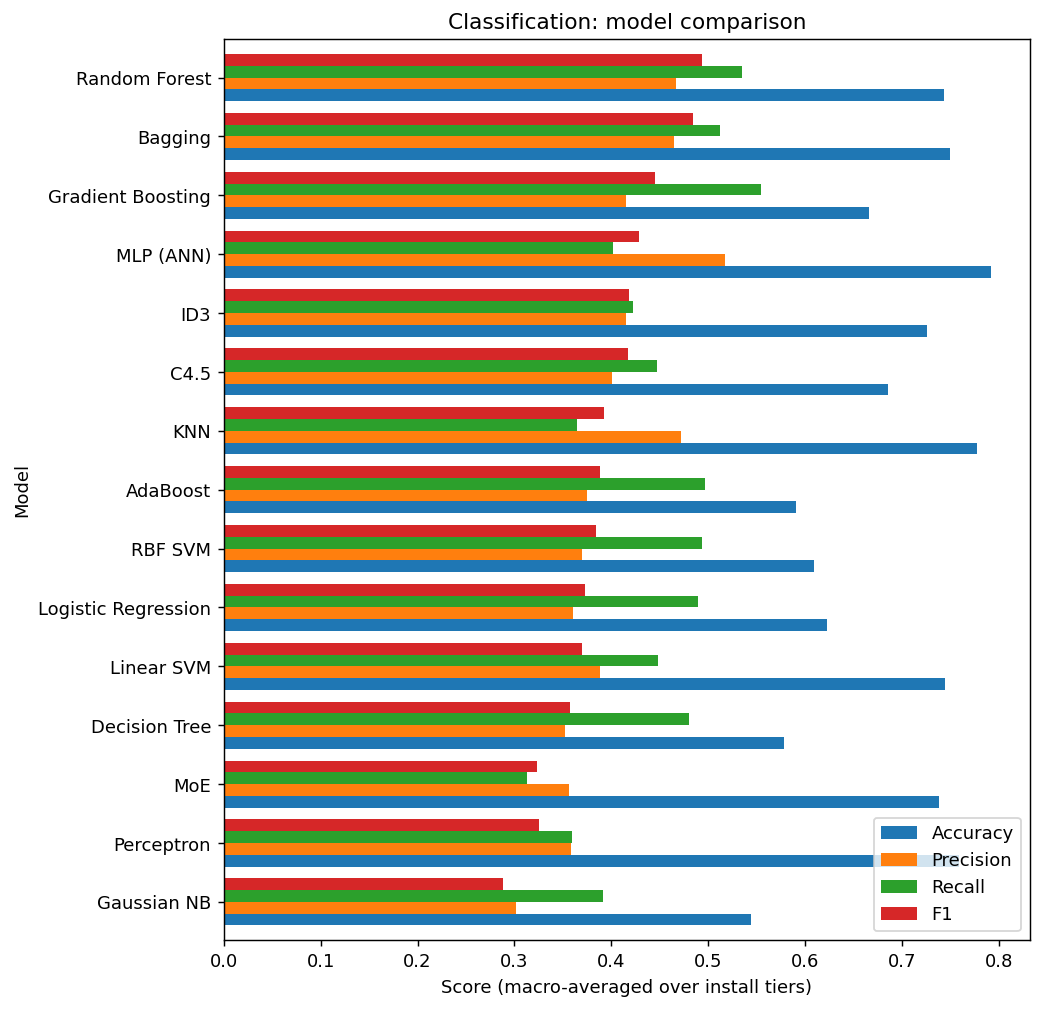

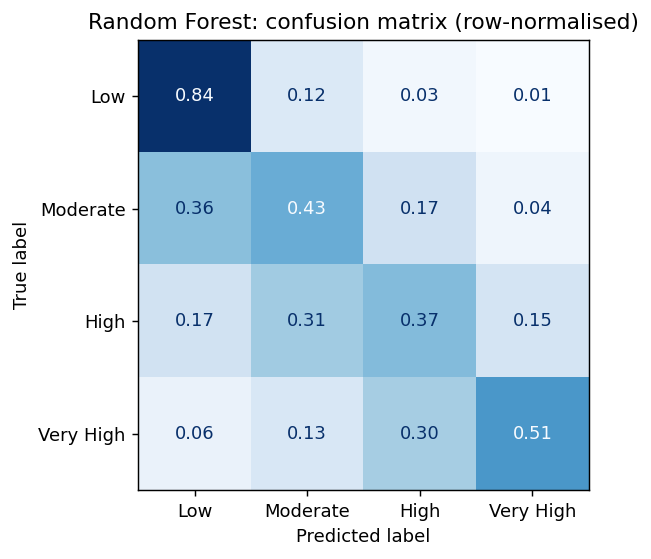

Best model: Random Forest - per-tier scores on its 462,589 test apps


,Precision,Recall,F1,Support
Low,0.912,0.837,0.873,359145
Moderate,0.345,0.426,0.381,66402
High,0.282,0.372,0.321,27453
Very High,0.328,0.506,0.398,9589


In [ ]:
report('clf')

**5b · Extra experiment: MLP with imbalance-aware losses.** The tiers are heavily skewed (Low ≈ 78% of apps, Very High ≈ 2%). A neural network trained with plain cross-entropy is pulled towards the majority tier, and the scikit-learn MLP above also early-stops on *accuracy*, which rewards predicting Low. So the MLP above may undersell what a neural network can do here. This section checks whether an MLP trained with a loss designed for imbalance can match or beat Random Forest.

Our label has 4 tiers, so we use the multi-class (softmax) versions of the two losses. With 2 classes they reduce to weighted BCE and binary focal loss.

* **Weighted cross-entropy:** $\mathcal{L} = -\,w_{y}\log p_{y}$, with $w_c = \frac{N}{K\,N_c}$ (`balanced`) or its square root (`sqrt`, a milder re-weighting).
* **Focal loss** (Lin et al., 2017): $\mathcal{L} = -\,\alpha_{y}\,(1-p_{y})^{\gamma}\log p_{y}$. The factor $(1-p_y)^\gamma$ shrinks the loss on easy, confidently classified apps (mostly Low), so training concentrates on the hard minority-tier apps. $\alpha_y$ is the same class weight (`None`, `sqrt` or `balanced`), and $\gamma$ is tuned.
* **Control:** the same PyTorch MLP with plain, unweighted cross-entropy. Any gain over this control is due to the loss, not to switching libraries.

All three use the same network (ReLU hidden layers + dropout, Adam, inputs standardised), the same protocol as every other model (3-fold grid search on the 150k tuning sample scored by macro-F1, then refit on all 1.85M training apps, scored on the full 20% test set), and early stopping on the **macro-F1** of a stratified 5% validation split of the training data. The test set is never used for any choice.

In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.neural_network import MLPClassifier
import inspect

DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
mlp_bal = 'sample_weight' in inspect.signature(MLPClassifier.fit).parameters

print(f'PyTorch {torch.__version__} on {DEV}  (Runtime > Change runtime type > T4 GPU makes this much faster)')
print(f'scikit-learn MLP in section 4 received balanced sample weights: {mlp_bal}')

class TorchMLP(ClassifierMixin, BaseEstimator):
    """Feed-forward classifier trained with cross-entropy or focal loss, with optional class weights.
    loss='ce'    + class_weight=None        -> plain cross-entropy
    loss='ce'    + class_weight='balanced'  -> weighted cross-entropy  (w_c = N / (K * N_c); 'sqrt' = its square root)
    loss='focal' + class_weight=...         -> focal loss, alpha_c = the same class weights, focusing parameter gamma
    Early stopping keeps the epoch with the best macro-F1 on a stratified validation split of the training data."""

    def __init__(self, loss='ce', class_weight=None, gamma=2.0, hidden=(256, 128), dropout=0.2, lr=1e-3,
                 weight_decay=1e-4, batch_size=1024, max_epochs=40, patience=6, val_fraction=0.05, random_state=SEED):
        self.loss, self.class_weight, self.gamma, self.hidden, self.dropout = loss, class_weight, gamma, hidden, dropout
        self.lr, self.weight_decay, self.batch_size, self.max_epochs = lr, weight_decay, batch_size, max_epochs
        self.patience, self.val_fraction, self.random_state = patience, val_fraction, random_state

    def _net(self, d_in, k):
        layers = []
        for h in self.hidden: layers += [nn.Linear(d_in, h), nn.ReLU(), nn.Dropout(self.dropout)]; d_in = h
        return nn.Sequential(*layers, nn.Linear(d_in, k)).to(DEV)

    def _weights(self, y, k):
        w = len(y) / (k * np.bincount(y, minlength=k).clip(1))
        w = {None: np.ones(k), 'balanced': w, 'sqrt': np.sqrt(w)}[self.class_weight]
        return torch.tensor(w, dtype=torch.float32, device=DEV)

    def _criterion(self, logits, y, w):
        logp = F.log_softmax(logits, 1).gather(1, y[:, None]).squeeze(1)    # log p_y
        loss = -logp if self.loss == 'ce' else -(1 - logp.exp()) ** self.gamma * logp
        wy = w[y]
        return (wy * loss).sum() / wy.sum()                                  # weighted mean, as in nn.CrossEntropyLoss

    def _tensor(self, X):
        return torch.as_tensor((np.asarray(X, np.float32) - self.mu_) / self.sd_, device=DEV)

    def fit(self, X, y):
        torch.manual_seed(self.random_state); np.random.seed(self.random_state)
        self.classes_ = np.unique(y); yi = np.searchsorted(self.classes_, y); k = len(self.classes_)
        tr, va = train_test_split(np.arange(len(yi)), test_size=self.val_fraction, stratify=yi, random_state=self.random_state)
        X = np.asarray(X, np.float32)
        self.mu_ = X[tr].mean(0); self.sd_ = X[tr].std(0); self.sd_[self.sd_ == 0] = 1
        Xt, yt, Xv = self._tensor(X[tr]), torch.as_tensor(yi[tr], dtype=torch.long, device=DEV), self._tensor(X[va])
        w = self._weights(yi[tr], k)
        self.net_ = self._net(X.shape[1], k)
        opt = torch.optim.Adam(self.net_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=2)
        best, best_state, wait, self.history_ = -1.0, None, 0, []
        for epoch in range(self.max_epochs):
            self.net_.train(); perm = torch.randperm(len(yt), device=DEV); total = 0.0
            for i in range(0, len(yt), self.batch_size):
                b = perm[i:i + self.batch_size]
                loss = self._criterion(self.net_(Xt[b]), yt[b], w)
                opt.zero_grad(); loss.backward(); opt.step(); total += loss.item() * len(b)
            f1 = skm.f1_score(yi[va], self._logits(Xv).argmax(1), average='macro')
            self.history_.append((epoch + 1, total / len(yt), f1)); sched.step(f1)
            if f1 > best: best, wait, best_state = f1, 0, {n: t.detach().clone() for n, t in self.net_.state_dict().items()}
            else:
                wait += 1
                if wait >= self.patience: break
        self.net_.load_state_dict(best_state); self.best_epoch_, self.val_f1_ = max(self.history_, key=lambda h: h[2])[0], best
        del Xt, yt, Xv
        if DEV == 'cuda': torch.cuda.empty_cache()
        return self

    @torch.no_grad()
    def _logits(self, X):
        self.net_.eval(); X = X if torch.is_tensor(X) else self._tensor(X)
        return torch.cat([self.net_(X[i:i + 65536]) for i in range(0, len(X), 65536)]).cpu().numpy()

    def predict_proba(self, X): return torch.softmax(torch.as_tensor(self._logits(X)), 1).numpy()
    def predict(self, X): return self.classes_[self._logits(X).argmax(1)]

MLP_LOSS = [
    S('MLP + CE (control)', TorchMLP(loss='ce'),
      {'hidden': [(128, 64), (256, 128)], 'weight_decay': [1e-5, 1e-4]}, 'torch'),
    S('MLP + weighted CE', TorchMLP(loss='ce', class_weight='balanced'),
      {'hidden': [(128, 64), (256, 128)], 'class_weight': ['sqrt', 'balanced'], 'weight_decay': [1e-5, 1e-4]}, 'torch'),
    S('MLP + focal loss', TorchMLP(loss='focal', class_weight='sqrt'),
      {'gamma': [1.0, 2.0, 3.0], 'class_weight': [None, 'sqrt', 'balanced']}, 'torch'),
]
for s in MLP_LOSS: run('clf', *s)

PyTorch 2.14.1+cu130 on cuda  (Runtime > Change runtime type > T4 GPU makes this much faster)
scikit-learn MLP in section 4 received balanced sample weights: False
MLP + CE (control)   F1=0.4030  Acc=0.7912  Prec=0.5261  Rec=0.3711  (581s) [restored]
MLP + weighted CE    F1=0.4757  Acc=0.7654  Prec=0.4702  Rec=0.4843  (127s)
MLP + focal loss     F1=0.4691  Acc=0.7629  Prec=0.4638  Rec=0.4794  (111s)


**5c · Can the MLP beat Random Forest?** Compares the three new MLPs with the original scikit-learn MLP and the two best tree ensembles: overall scores, per-tier F1 (the minority tiers are where the losses should help), and confusion matrices of the best new MLP next to Random Forest. A paired bootstrap on the full test set (1,000 resamples of the 462k test apps) gives a 95% confidence interval for the macro-F1 gap between the best MLP and Random Forest. If the interval excludes 0, the difference is real and not resampling noise.

,Accuracy,Precision,Recall,Macro-F1,F1 Low,F1 Moderate,F1 High,F1 Very High
Random Forest,0.7435,0.4668,0.5351,0.4932,0.8729,0.3810,0.3209,0.3980
Bagging,0.7494,0.4647,0.5127,0.4847,0.8771,0.3725,0.3097,0.3795
MLP + weighted CE,0.7654,0.4702,0.4843,0.4757,0.8875,0.3361,0.2859,0.3934
MLP + focal loss,0.7629,0.4638,0.4794,0.4691,0.8857,0.3315,0.2729,0.3863
MLP (ANN),0.7926,0.5173,0.4018,0.4285,0.8964,0.2137,0.2204,0.3834
MLP + CE (control),0.7912,0.5261,0.3711,0.4030,0.8942,0.1804,0.2038,0.3334


Model,Selected hyperparameters,CV macro-F1
MLP + CE (control),"hidden=(256, 128), weight_decay=1e-05",0.3769
MLP + weighted CE,"class_weight=sqrt, hidden=(256, 128), weight_decay=1e-05",0.4397
MLP + focal loss,"class_weight=sqrt, gamma=2.0",0.4396


Best imbalance-aware MLP: MLP + weighted CE
Macro-F1 gap vs Random Forest = -0.0175  (95% bootstrap CI -0.0200 to -0.0151)
Gain over the plain-CE control MLP = +0.0728
Verdict: Random Forest is still significantly better: the re-weighted losses do not close the gap.


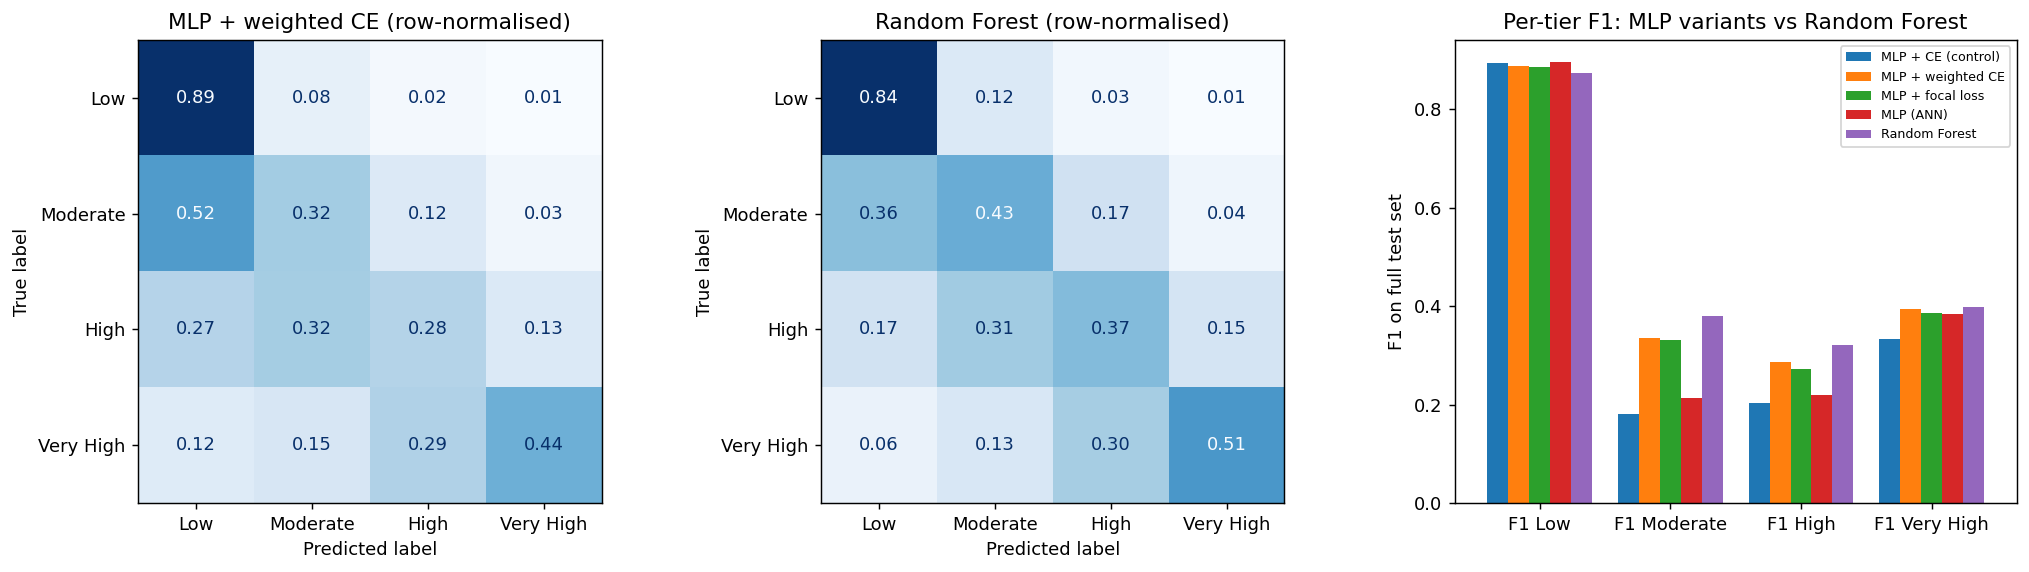

In [ ]:
d = D['clf']; yte = d['yte']; K = len(CLASS_NAMES)
NEW = [s[0] for s in MLP_LOSS]
SHOW = NEW + ['MLP (ANN)', 'Random Forest', 'Bagging']
res = pd.DataFrame(RESULTS).query("Task == 'clf' and Model in @SHOW").set_index('Model').loc[SHOW]
tiers = pd.DataFrame({m: skm.f1_score(yte, PRED[('clf', m)], average=None, labels=range(K)) for m in SHOW}, index=[f'F1 {c}' for c in CLASS_NAMES]).T
cmp = pd.concat([res[['Accuracy', 'Precision', 'Recall', 'F1']].rename(columns={'F1': 'Macro-F1'}), tiers], axis=1).sort_values('Macro-F1', ascending=False)
display(cmp.style.format(precision=4).highlight_max(props='font-weight:bold;background-color:#d9ead3'))
display(pd.DataFrame(TUNING).query("Task == 'clf' and Model in @NEW")[['Model', 'Selected hyperparameters', 'CV macro-F1']].style.format(precision=4).hide(axis='index'))

def macro_f1(t, p):                                   # fast macro-F1 from a confusion matrix (for the bootstrap)
    cm = np.bincount(t * K + p, minlength=K * K).reshape(K, K); tp = np.diag(cm)
    return np.mean(2 * tp / np.maximum(cm.sum(0) + cm.sum(1), 1))

best_mlp = cmp.loc[NEW, 'Macro-F1'].idxmax()
pm, pr, t = PRED[('clf', best_mlp)].astype(np.int64), PRED[('clf', 'Random Forest')].astype(np.int64), yte.astype(np.int64)
rng = np.random.default_rng(SEED)
gaps = np.array([macro_f1(t[i], pm[i]) - macro_f1(t[i], pr[i]) for i in (rng.integers(0, len(t), len(t)) for _ in range(1000))])
gap, (lo, hi) = macro_f1(t, pm) - macro_f1(t, pr), np.percentile(gaps, [2.5, 97.5])
print(f'Best imbalance-aware MLP: {best_mlp}')
print(f'Macro-F1 gap vs Random Forest = {gap:+.4f}  (95% bootstrap CI {lo:+.4f} to {hi:+.4f})')
print(f'Gain over the plain-CE control MLP = {macro_f1(t, pm) - macro_f1(t, PRED[("clf", "MLP + CE (control)")].astype(np.int64)):+.4f}')
print('Verdict:', 'the MLP significantly beats Random Forest.' if lo > 0 else
      'Random Forest is still significantly better: the re-weighted losses do not close the gap.' if hi < 0 else
      'no significant difference: the MLP matches Random Forest but does not beat it.')

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, m in zip(ax[:2], [best_mlp, 'Random Forest']):
    skm.ConfusionMatrixDisplay.from_predictions(yte, PRED[('clf', m)], display_labels=CLASS_NAMES, normalize='true',
                                                values_format='.2f', cmap='Blues', colorbar=False, ax=a)
    a.set_title(f'{m} (row-normalised)')
tiers.loc[[m for m in SHOW if m != 'Bagging']].T.plot.bar(ax=ax[2], width=.8, rot=0)
ax[2].set(ylabel='F1 on full test set', title='Per-tier F1: MLP variants vs Random Forest'); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

**6 · Regression models.** Tunes and trains the 12 regressors (MoE uses linear-regression experts) on `log(1 + Maximum Installs)`, using the same tier-stratified split and subsamples as the classifiers.

In [ ]:
REG = [
    S('Linear Regression', LinearRegression(n_jobs=-1)),
    S('Bayesian Ridge', BayesianRidge()),
    S('KNN', KNeighborsRegressor(weights='distance', n_jobs=-1), {'n_neighbors': [21, 31, 45]}, 'knn'),
    S('Linear SVR', LinearSVR(loss='squared_epsilon_insensitive', dual=False, max_iter=2000, random_state=SEED),
      {'C': [0.01, 0.1, 1.0], 'epsilon': [0, 0.2, 0.5]}),
    S('RBF SVR', SVR(cache_size=2000), {'C': [0.3, 1, 3], 'gamma': ['scale', 0.01, 0.1], 'epsilon': [0.25, 0.5, 1.0]}, 'svm'),
    S('Decision Tree', DecisionTreeRegressor(random_state=SEED), {'max_depth': [10, 12, 14, 16], 'min_samples_leaf': [10, 20, 50]}),
    S('Random Forest', RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEED),
      {'max_depth': [15, 25, None], 'max_features': ['sqrt', 0.33], 'min_samples_leaf': [5, 10, 20]}),
    S('AdaBoost', AdaBoostRegressor(DecisionTreeRegressor(), n_estimators=100, random_state=SEED),
      {'estimator__max_depth': [4, 6], 'learning_rate': [0.1, 0.5], 'loss': ['linear', 'square']}),
    S('Gradient Boosting', HistGradientBoostingRegressor(max_iter=1000, early_stopping=True, n_iter_no_change=20, random_state=SEED),
      {'learning_rate': [0.02, 0.05], 'max_leaf_nodes': [127, 255, 511]}),
    S('Bagging', BaggingRegressor(DecisionTreeRegressor(), n_estimators=30, n_jobs=-1, random_state=SEED),
      {'estimator__min_samples_leaf': [5, 20, 50]}),
    S('MLP (ANN)', MLPRegressor(batch_size=1024, early_stopping=True, validation_fraction=.05, n_iter_no_change=10, max_iter=100, random_state=SEED),
      {'hidden_layer_sizes': [(64,), (128, 64), (256, 128)], 'alpha': [1e-4, 1e-3]}),
    S('MoE', MoERegressor(), {'n_experts': [4, 8, 16]}),
]
for s in REG: run('reg', *s)

Linear Regression    F1=0.3121  Acc=0.7695  Prec=0.4411  Rec=0.3018  (7s) [restored]
Bayesian Ridge       F1=0.3296  Acc=0.7723  Prec=0.4706  Rec=0.3141  (6s) [restored]
KNN                  F1=0.3409  Acc=0.7810  Prec=0.5538  Rec=0.3279  (0s) [restored]
Linear SVR           F1=0.3295  Acc=0.7723  Prec=0.4695  Rec=0.3141  (4s) [restored]
RBF SVR              F1=0.3672  Acc=0.7783  Prec=0.5314  Rec=0.3449  (115s) [restored]
Decision Tree        F1=0.3578  Acc=0.7761  Prec=0.5340  Rec=0.3391  (39s) [restored]
Random Forest        F1=0.3974  Acc=0.7930  Prec=0.6000  Rec=0.3694  (762s) [restored]
AdaBoost             F1=0.3023  Acc=0.7675  Prec=0.6093  Rec=0.3075  (1684s) [restored]
Gradient Boosting    F1=0.4039  Acc=0.7886  Prec=0.5793  Rec=0.3725  (904s) [restored]
Bagging              F1=0.4241  Acc=0.7941  Prec=0.5890  Rec=0.3907  (841s) [restored]
MLP (ANN)            F1=0.3966  Acc=0.7853  Prec=0.5646  Rec=0.3672  (618s) [restored]
MoE                  F1=0.3370  Acc=0.7718  Prec=0.

**7 · Regression results.** Same layout as the classification results; accuracy, precision, recall and F1 are computed on the 4 install tiers, alongside R², RMSE and MAE in log space.

Model,Train rows,Fit (s),Scored on,Accuracy,Precision,Recall,F1,F1 (common 50k),R2,RMSE,MAE
Bagging,"1,850,355",841,full test,0.7941,0.5890,0.3907,0.4241,0.4216,0.5196,2.1888,1.7013
Gradient Boosting,"1,850,355",904,full test,0.7886,0.5793,0.3725,0.4039,0.4051,0.5043,2.2235,1.7601
MLP (ANN),"1,850,355",618,full test,0.7853,0.5646,0.3672,0.3966,0.3951,0.4846,2.2672,1.7953
Random Forest,"1,850,355",762,full test,0.7930,0.6000,0.3694,0.3974,0.3930,0.5185,2.1915,1.7224
RBF SVR,"50,000",115,full test,0.7783,0.5314,0.3449,0.3672,0.3683,0.4200,2.4052,1.9120
Decision Tree,"1,850,355",39,full test,0.7761,0.5340,0.3391,0.3578,0.3552,0.4162,2.4131,1.9186
KNN,"200,000",0,full test,0.7810,0.5538,0.3279,0.3409,0.3388,0.4206,2.4038,1.8949
MoE,"1,850,355",100,full test,0.7718,0.4722,0.3200,0.3370,0.3362,0.3510,2.5443,2.0449
Linear SVR,"1,850,355",4,full test,0.7723,0.4695,0.3141,0.3295,0.3301,0.3307,2.5836,2.0786
Bayesian Ridge,"1,850,355",6,full test,0.7723,0.4706,0.3141,0.3296,0.3299,0.3309,2.5833,2.0777


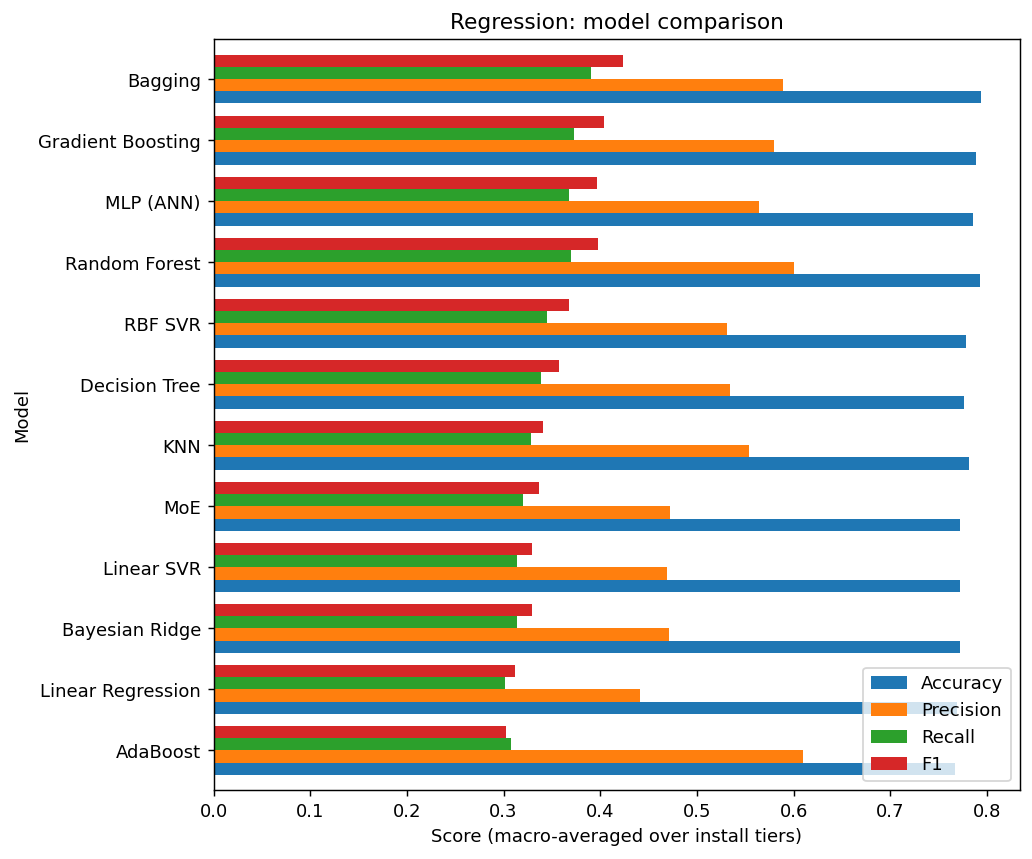

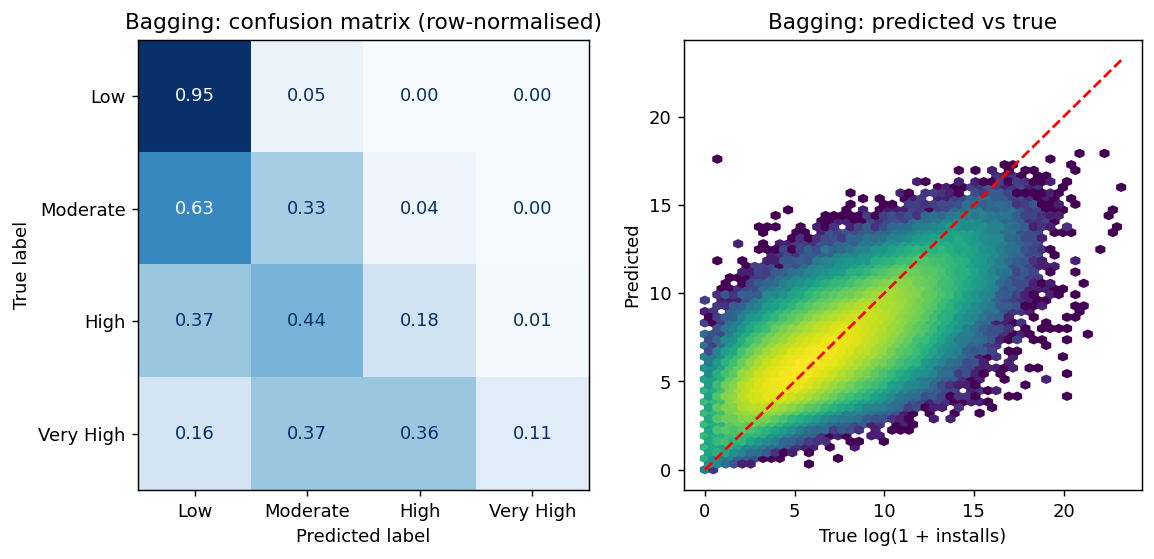

Best model: Bagging - per-tier scores on its 462,589 test apps


,Precision,Recall,F1,Support
Low,0.864,0.945,0.903,359145
Moderate,0.391,0.329,0.357,66402
High,0.397,0.180,0.247,27453
Very High,0.704,0.109,0.188,9589


In [ ]:
report('reg')

**8 · Final comparison table.** One table with every model of both tasks (best per task in bold) and a LaTeX version for the ACM report.

In [ ]:
FINAL = pd.DataFrame(RESULTS).assign(Task=lambda d: d.Task.map({'clf': 'Classification', 'reg': 'Regression'}))
FINAL = FINAL.sort_values(['Task', 'F1 (common 50k)'], ascending=[True, False]).reset_index(drop=True)[['Task', 'Model', 'Scored on', 'Accuracy', 'Precision', 'Recall', 'F1', 'F1 (common 50k)', 'R2', 'RMSE', 'MAE', 'Train rows', 'Fit (s)']]
top = FINAL.groupby('Task')['F1 (common 50k)'].idxmax().values
display(FINAL.style.format({'Train rows': '{:,.0f}', 'Fit (s)': '{:.0f}'}, precision=4, na_rep='–').hide(axis='index')
        .apply(lambda r: ['font-weight:bold;background-color:#d9ead3' if r.name in top else ''] * len(r), axis=1))
print(FINAL.drop(columns=['Train rows', 'Fit (s)']).to_latex(index=False, float_format='%.4f', na_rep='--', caption='Test performance of all models (macro-averaged over install tiers).', label='tab:results'))

Task,Model,Scored on,Accuracy,Precision,Recall,F1,F1 (common 50k),R2,RMSE,MAE,Train rows,Fit (s)
Classification,Random Forest,full test,0.7435,0.4668,0.5351,0.4932,0.4944,–,–,–,"1,850,355",884
Classification,Bagging,full test,0.7494,0.4647,0.5127,0.4847,0.4848,–,–,–,"1,850,355",1000
Classification,MLP + weighted CE,full test,0.7654,0.4702,0.4843,0.4757,0.4780,–,–,–,"1,850,355",127
Classification,MLP + focal loss,full test,0.7629,0.4638,0.4794,0.4691,0.4676,–,–,–,"1,850,355",111
Classification,Gradient Boosting,full test,0.6658,0.4155,0.5547,0.4453,0.4451,–,–,–,"1,850,355",567
Classification,MLP (ANN),full test,0.7926,0.5173,0.4018,0.4285,0.4286,–,–,–,"1,850,355",613
Classification,ID3,full test,0.7265,0.4153,0.4220,0.4185,0.4135,–,–,–,"1,850,355",66
Classification,C4.5,full test,0.6860,0.4012,0.4467,0.4172,0.4131,–,–,–,"1,850,355",280
Classification,MLP + CE (control),full test,0.7912,0.5261,0.3711,0.4030,0.4028,–,–,–,"1,850,355",581
Classification,KNN,full test,0.7779,0.4720,0.3647,0.3929,0.3895,–,–,–,"200,000",0


\begin{table}
\caption{Test performance of all models (macro-averaged over install tiers).}
\label{tab:results}
\begin{tabular}{lllrrrrrrrr}
\toprule
Task & Model & Scored on & Accuracy & Precision & Recall & F1 & F1 (common 50k) & R2 & RMSE & MAE \\
\midrule
Classification & Random Forest & full test & 0.7435 & 0.4668 & 0.5351 & 0.4932 & 0.4944 & -- & -- & -- \\
Classification & Bagging & full test & 0.7494 & 0.4647 & 0.5127 & 0.4847 & 0.4848 & -- & -- & -- \\
Classification & MLP + weighted CE & full test & 0.7654 & 0.4702 & 0.4843 & 0.4757 & 0.4780 & -- & -- & -- \\
Classification & MLP + focal loss & full test & 0.7629 & 0.4638 & 0.4794 & 0.4691 & 0.4676 & -- & -- & -- \\
Classification & Gradient Boosting & full test & 0.6658 & 0.4155 & 0.5547 & 0.4453 & 0.4451 & -- & -- & -- \\
Classification & MLP (ANN) & full test & 0.7926 & 0.5173 & 0.4018 & 0.4285 & 0.4286 & -- & -- & -- \\
Classification & ID3 & full test & 0.7265 & 0.4153 & 0.4220 & 0.4185 & 0.4135 & -- & -- & -- \\
Classif

**9 · Selected hyperparameters.** The grid-search winner and its cross-validated score for every model, for the experimental-setup section of the report.

In [ ]:
display(pd.DataFrame(TUNING).assign(Task=lambda d: d.Task.map({'clf': 'Classification', 'reg': 'Regression'})).style
        .format(precision=4, na_rep='–').hide(axis='index'))

Task,Model,Selected hyperparameters,CV macro-F1,CV RMSE
Classification,Logistic Regression,C=0.1,0.3745,–
Classification,Perceptron,"alpha=1e-05, penalty=l1",0.3516,–
Classification,KNN,n_neighbors=11,0.3767,–
Classification,Gaussian NB,var_smoothing=0.001,0.2976,–
Classification,Linear SVM,C=0.1,0.3685,–
Classification,RBF SVM,"C=30, gamma=0.01",0.3751,–
Classification,Decision Tree,"criterion=gini, max_depth=8, min_samples_leaf=50",0.3485,–
Classification,ID3,fixed (not tuned),–,–
Classification,C4.5,ccp_alpha=1e-06,0.3735,–
Classification,Random Forest,"max_depth=None, max_features=0.33, min_samples_leaf=5",0.4497,–
